<a href="https://colab.research.google.com/github/Nihat0311/Machine-Learning/blob/main/RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay)
from sklearn.ensemble import RandomForestClassifier
import os
from sklearn.inspection import permutation_importance

In [ ]:
!curl -L -o default-of-credit-card-clients-dataset.zip \
  https://www.kaggle.com/api/v1/datasets/download/uciml/default-of-credit-card-clients-dataset


!unzip -q default-of-credit-card-clients-dataset.zip


df = pd.read_csv('UCI_Credit_Card.csv')
df = df.rename(columns={"default.payment.next.month": "default"})

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 1001k  100 1001k    0     0  1718k      0 --:--:-- --:--:-- --:--:-- 4678k


In [ ]:
df


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,1,3,1,39,0,0,0,0,...,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,1,3,2,43,-1,-1,-1,-1,...,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,1,2,2,37,4,3,2,-1,...,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,1,3,1,41,1,-1,0,0,...,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


In [ ]:
df['default'].value_counts()

,count
default,
0,23364
1,6636


In [ ]:
X=df.drop('default',axis=1)
y=df['default'].copy()

In [ ]:
num_feature=X.select_dtypes(include=np.number).columns

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
num_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
])
transformer=ColumnTransformer([
    ('num',num_pipeline,num_feature)
])
full_pipeline=Pipeline([
    ('transformer',transformer),
    ('model',RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42
    ))
])

full_pipeline.fit(X_train,y_train)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'],
      dtype='object'))])),
                ('model',
                 RandomForestClassifier(max_depth=10, random_state=42))])

In [ ]:
full_pipeline.score(X_test,y_test)

0.8171666666666667

In [ ]:
full_pipeline.score(X_train,y_train)

0.857875

In [ ]:
y_pred=full_pipeline.predict(X_test)
confusion_matrix(y_test,y_pred)

array([[4431,  242],
       [ 855,  472]])

In [ ]:
small_X=X_train.sample(frac=0.98,random_state=42)
small_y=y_train.loc[small_X.index]

In [ ]:
dt_1=Pipeline([
    ('transformer',transformer),
    ('model',DecisionTreeClassifier(max_depth=10,random_state=42))
])

dt_2=Pipeline([
    ('transformer',transformer),
    ('model',DecisionTreeClassifier(max_depth=10,random_state=42))
])

In [ ]:
dt_1.fit(X_train,y_train)
dt_2.fit(small_X,small_y)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'],
      dtype='object'))])),
                ('model',
                 DecisionTreeClassifier(max_depth=10, random_state=42))])

In [ ]:
y_pred1=dt_1.predict(X_test)
y_pred2=dt_2.predict(X_test)

In [ ]:
diff_count=np.sum(y_pred1!=y_pred2)
diff_count

np.int64(236)

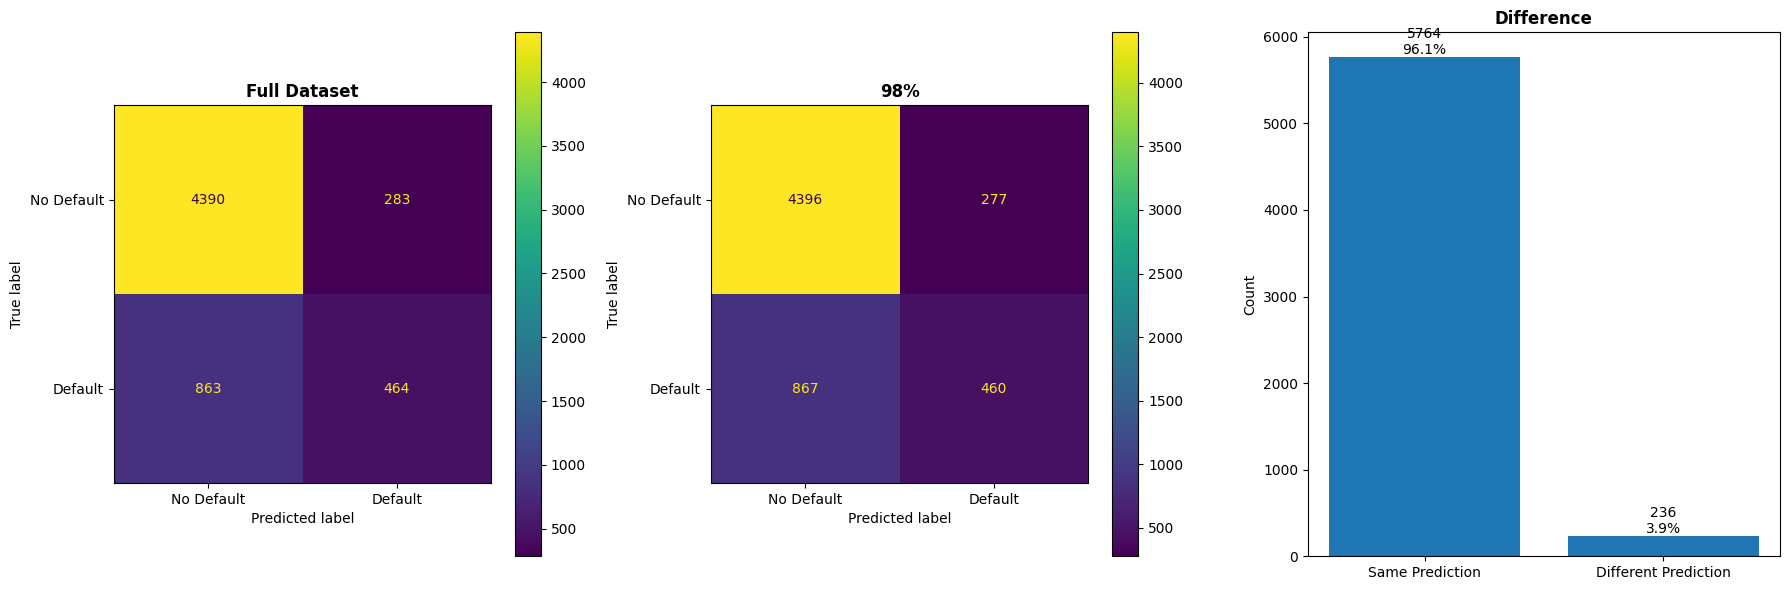

In [ ]:
fig, ax=plt.subplots(1,3,figsize=(18,6))

cm=confusion_matrix(y_test,y_pred1)
ConfusionMatrixDisplay(cm,display_labels=['No Default','Default']).plot(ax=ax[0])
ax[0].set_title('Full Dataset', fontsize=12, fontweight='bold')

cm1=confusion_matrix(y_test,y_pred2)
ConfusionMatrixDisplay(cm1,display_labels=['No Default','Default']).plot(ax=ax[1])
ax[1].set_title('98%', fontsize=12, fontweight='bold')

values=[len(y_pred1)-diff_count,diff_count]
labels=['Same Prediction','Different Prediction']
bars=ax[2].bar(labels,values)
ax[2].set_title('Difference', fontsize=12, fontweight='bold')
ax[2].set_ylabel('Count')

percent_labels=[f"{v}\n{v / len(y_pred1)*100:.1f}%" for v in values]
ax[2].bar_label(bars,labels=percent_labels)

plt.tight_layout()
plt.show()

In [ ]:
rf_1=Pipeline([
    ('transformer',transformer),
    ('model',RandomForestClassifier(n_estimators=100,max_depth=10,random_state=42))
])

rf_2=Pipeline([
    ('transformer',transformer),
    ('model',RandomForestClassifier(n_estimators=100,max_depth=10,random_state=42))
])

In [ ]:
rf_1.fit(X_train,y_train)
rf_2.fit(small_X,small_y)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'],
      dtype='object'))])),
                ('model',
                 RandomForestClassifier(max_depth=10, random_state=42))])

In [ ]:
y_pred1=rf_1.predict(X_test)
y_pred2=rf_2.predict(X_test)

In [ ]:
diff_count=np.sum(y_pred1!=y_pred2)
diff_count

np.int64(70)

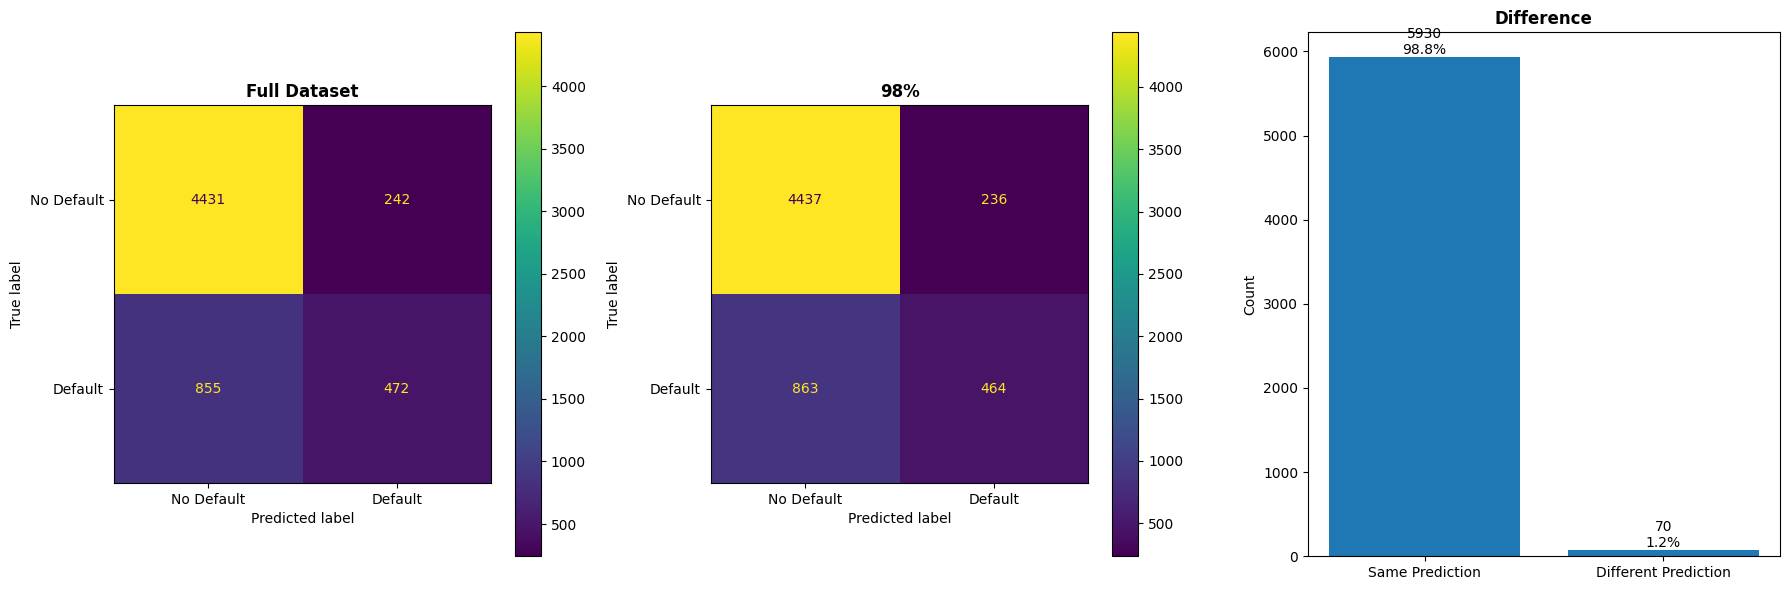

In [ ]:
fig, ax=plt.subplots(1,3,figsize=(18,6))

cm=confusion_matrix(y_test,y_pred1)
ConfusionMatrixDisplay(cm,display_labels=['No Default','Default']).plot(ax=ax[0])
ax[0].set_title('Full Dataset', fontsize=12, fontweight='bold')

cm1=confusion_matrix(y_test,y_pred2)
ConfusionMatrixDisplay(cm1,display_labels=['No Default','Default']).plot(ax=ax[1])
ax[1].set_title('98%', fontsize=12, fontweight='bold')

values=[len(y_pred1)-diff_count,diff_count]
labels=['Same Prediction','Different Prediction']
bars=ax[2].bar(labels,values)
ax[2].set_title('Difference', fontsize=12, fontweight='bold')
ax[2].set_ylabel('Count')

percent_labels=[f"{v}\n{v / len(y_pred1)*100:.1f}%" for v in values]
ax[2].bar_label(bars,labels=percent_labels)

plt.tight_layout()
plt.show()

In [ ]:
oob_model=Pipeline([
    ('transformer',transformer),
    ('model',RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        bootstrap=True,
        oob_score=True
    ))
])

oob_model.fit(X_train,y_train)

Pipeline(steps=[('transformer',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'],
      dtype='object'))])),
                ('model',
                 RandomForestClassifier(max_depth=10, oob_score=True,
                                        random_state=42))])

In [ ]:
oob_score=oob_model.named_steps['model'].oob_score_
oob_score

0.8205833333333333

In [ ]:
feature_importances=oob_model.named_steps['model'].feature_importances_
feature_names=oob_model.named_steps['transformer'].get_feature_names_out()
importance_df=pd.DataFrame({'Feature':feature_names,'Importance':feature_importances}).sort_values(by='Importance',ascending=False)
importance_df

,Feature,Importance
6,num__PAY_0,0.230638
7,num__PAY_2,0.114107
8,num__PAY_3,0.075072
10,num__PAY_5,0.045728
9,num__PAY_4,0.045040
18,num__PAY_AMT1,0.037480
1,num__LIMIT_BAL,0.036289
12,num__BILL_AMT1,0.035558
0,num__ID,0.031507
19,num__PAY_AMT2,0.031059


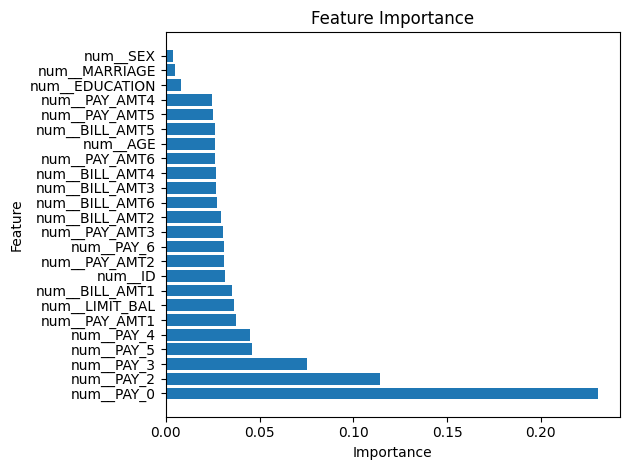

In [ ]:
plt.barh(importance_df['Feature'],importance_df['Importance'])
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Feature Importance')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.inspection import permutation_importance

permutation_importance=permutation_importance(
    oob_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42
)

feature_names=oob_model.named_steps['transformer'].get_feature_names_out()
perm_importance=permutation_importance.importances_mean

df_perm=pd.DataFrame({'Feature':feature_names,'Importance':perm_importance}).sort_values(by='Importance',ascending=False)
df_perm

,Feature,Importance
6,num__PAY_0,0.055967
12,num__BILL_AMT1,0.001433
11,num__PAY_6,0.001367
22,num__PAY_AMT5,0.000633
23,num__PAY_AMT6,0.000433
18,num__PAY_AMT1,0.000367
16,num__BILL_AMT5,0.000233
15,num__BILL_AMT4,0.000167
17,num__BILL_AMT6,0.000167
2,num__SEX,0.000133


In [ ]:
plt.barh()